# Diurnal cycles of sun-induced chlorophyll fluorescence (F760) simulated with SCOPE

**Paper:** C. van der Tol, M. Rossini, S. Cogliati, W. Verhoef, R. Colombo, U. Rascher, G. Mohammed (2016),
*A model and measurement comparison of diurnal cycles of sun-induced chlorophyll fluorescence of crops*,
Remote Sensing of Environment 186, 663–677. [DOI 10.1016/j.rse.2016.09.021](https://doi.org/10.1016/j.rse.2016.09.021)

**Code:** the authors' model repository [Christiaanvandertol/SCOPE](https://github.com/Christiaanvandertol/SCOPE), pinned tag **2.1**
(commit `2c2b89b5884dd99a872c3e1430cf59761c8541cb`), GNU GPL v3.

**Scope (partial demonstration, simulation-only).** The paper combined *field measurements* over rice and
alfalfa with SCOPE simulations. The field datasets are **not public**, so the measurement comparisons cannot
be reproduced here. This notebook reproduces the paper's **simulation core**: half-hourly diurnal cycles of
canopy fluorescence radiance at 760 nm (F760) simulated with SCOPE under (i) a **constant** ChlF emission
efficiency at photosystem level versus (ii) the **variable** efficiency computed by the coupled
electron-transport/photosynthesis/fluorescence model — plus (iii) the theoretical **maximum** efficiency —
driven by the model's **bundled example time-series inputs** (`input/dataset mSCOPE_ts`).

**How the author code is used.** SCOPE 2.1 is **MATLAB** code; the original numerical sources are run
headlessly in **GNU Octave** on Colab (no re-implementation of the science). A few *documented compatibility
patches* (input-file I/O for Octave, and a 4-line scenario hook) are applied and shown explicitly below; in
their default state they do not change model behavior.

**AI-assisted adaptation statement:** the compatibility patches and the scenario operationalization were
written by AI (not by the authors). The executed example and listed checks were validated, but untested
behavior is not guaranteed. The constant used for scenario (i) is an AI-defined operationalization because
the paper's full text could not be retrieved (see *Interpretation*).

**日本語 summary:** このノートブックは、van der Tol ら (2016, RSE) の**シミュレーション部分**のみを再現します。
圃場データは公開されていないため測定との比較は対象外です。著者らの MATLAB モデル **SCOPE**（タグ 2.1、
数値計算本体は無改変）を Colab の **Octave**（CPU のみ）で headless 実行し、同梱の半時間値例題入力
`input/dataset mSCOPE_ts` で F760 の日変化を 3 つの ChlF 放射効率シナリオ（一定・変動・理論最大）で比較します。

**Execution status:** executed on Colab **CPU**. No GPU is involved (SCOPE has no GPU code path).
Expected end-to-end ≈ 10–20 min; total download ≈ 8 MB (pinned sparse checkout; largest file is the
5.3 MB atmosphere file).

## Runtime selection

**Select the `CPU` runtime in Colab (Runtime → Change runtime type → CPU).**
SCOPE is a deterministic radiative-transfer / energy-balance model operating on small (~2000-element)
spectral vectors per half-hourly time step; the repository contains no GPU code (no CUDA, `gpuArray`,
or parallel constructs). CPU is the faithful and recommended runtime and the only validated one.

**日本語:** GPU は不要です（SCOPE に GPU コードは存在しません）。CPU ランタイムを選択してください。
目安時間は約 10〜20 分、ダウンロードは約 8 MB です。

### 3. Install GNU Octave

The authors' SCOPE 2.1 is MATLAB code. We run the original `.m` sources headlessly in **GNU Octave**
(an open-source MATLAB-language interpreter): the model files (`src/RTMs`, `src/fluxes`, `src/supporting`)
are used exactly as published. This cell installs Octave from the Ubuntu repositories and prints its version
(~1–3 min; the install log tail is shown for transparency).

**日本語:** 著者らの MATLAB コードを動かすため Octave をインストールします（約1〜3分）。

In [ ]:
%%bash
export DEBIAN_FRONTEND=noninteractive
apt-get update -qq > /tmp/apt_update.log 2>&1
apt-get install -y -qq octave > /tmp/octave_install.log 2>&1
echo "octave install exit: $?"
tail -2 /tmp/octave_install.log
octave --version | head -1

octave install exit: 0
/sbin/ldconfig.real: /usr/local/lib/libtbbbind_2_0.so.3 is not a symbolic link

GNU Octave, version 8.4.0


octave: X11 DISPLAY environment variable not set
octave: disabling GUI features


### 4. Acquire the pinned author code + example inputs (inside Colab only)

The repository is retrieved **here in the notebook** as a **pinned partial clone** (blobless, sparse
checkout) of `Christiaanvandertol/SCOPE` at tag **2.1** = commit `2c2b89b5884dd99a872c3e1430cf59761c8541cb`. Only `SCOPE.m`,
`set_parameter_filenames.csv`, `src/`, `input/` and the licence file are checked out — documentation
builds, the 7.5 MB Windows executable and old verification outputs are excluded (≈8 MB total).
The checked-out commit is asserted against the pin.

**日本語:** 著者リポジトリをタグ 2.1（コミット固定）で部分取得します（約8 MB）。コミット一致を検証します。

In [ ]:
%%bash
cd /content
rm -rf /content/SCOPE
git clone --quiet --filter=blob:none --no-checkout --depth 1 \
    --branch 2.1 https://github.com/Christiaanvandertol/SCOPE SCOPE 2>&1 | tail -1
cd SCOPE
git config core.sparseCheckout true
printf 'SCOPE.m\nset_parameter_filenames.csv\nsrc/**\ninput/**\nGNU_General_Public_Licence.txt\n' > .git/info/sparse-checkout
git checkout --quiet 2.1
HEAD_SHA=$(git rev-parse HEAD)
echo "checked-out commit: $HEAD_SHA"
test "$HEAD_SHA" = "2c2b89b5884dd99a872c3e1430cf59761c8541cb" && echo "PIN VERIFIED" || { echo "PIN MISMATCH"; exit 1; }
du -sh /content/SCOPE
ls "input/dataset mSCOPE_ts/"

checked-out commit: 2c2b89b5884dd99a872c3e1430cf59761c8541cb
PIN VERIFIED
8.6M	/content/SCOPE
ec_berkeley.csv
input_mSCOPE_timeseries.csv
interpolatable.csv
ts_input.csv


### 4.2 Verify the downloaded bytes

Check the expected key files and their exact sizes (recorded from the pinned GitHub tree), and reject
Git-LFS pointer files masquerading as payloads.

**日本語:** 固定コミットのファイルサイズ検証と LFS ポインタでないことの確認を行います。

In [ ]:
import os

SCOPE = "/content/SCOPE"
expected = {
    "SCOPE.m": 20906,
    "set_parameter_filenames.csv": 62,
    "src/RTMs/RTMf.m": 12737,
    "src/fluxes/biochemical.m": 24506,
    "input/input_data_default.csv": 801,
    "input/setoptions.csv": 250,
    "input/dataset mSCOPE_ts/ts_input.csv": 17536,
    "input/dataset mSCOPE_ts/interpolatable.csv": 194,
    "input/dataset mSCOPE_ts/input_mSCOPE_timeseries.csv": 387,
    "input/dataset mSCOPE_ts/ec_berkeley.csv": 223214,
    "input/radiationdata/FLEX-S3_std.atm": 5260349,
    "input/fluspect_parameters/Optipar2021_ProspectPRO_CX.mat": 94368,
}
ok = True
for rel, size in expected.items():
    p = os.path.join(SCOPE, rel)
    actual = os.path.getsize(p) if os.path.isfile(p) else 0
    good = actual == size
    ok &= good
    print(f"{'OK ' if good else 'FAIL'} {rel:58s} {actual:>9d} bytes")
assert ok, "byte-size verification failed"
for rel in ["input/fluspect_parameters/Optipar2021_ProspectPRO_CX.mat", "input/radiationdata/FLEX-S3_std.atm"]:
    with open(os.path.join(SCOPE, rel), "rb") as fh:
        head = fh.read(16)
    assert not head.startswith(b"version https://git-lfs"), f"LFS pointer not smudged: {rel}"
print("all pinned file sizes verified; no LFS pointers")

OK  SCOPE.m                                                        20906 bytes
OK  set_parameter_filenames.csv                                       62 bytes
OK  src/RTMs/RTMf.m                                                12737 bytes
OK  src/fluxes/biochemical.m                                       24506 bytes
OK  input/input_data_default.csv                                     801 bytes
OK  input/setoptions.csv                                             250 bytes
OK  input/dataset mSCOPE_ts/ts_input.csv                           17536 bytes
OK  input/dataset mSCOPE_ts/interpolatable.csv                       194 bytes
OK  input/dataset mSCOPE_ts/input_mSCOPE_timeseries.csv              387 bytes
OK  input/dataset mSCOPE_ts/ec_berkeley.csv                       223214 bytes
OK  input/radiationdata/FLEX-S3_std.atm                          5260349 bytes
OK  input/fluspect_parameters/Optipar2021_ProspectPRO_CX.mat       94368 bytes
all pinned file sizes verified; no LFS pointers


### 5. Documented Octave-compatibility patches (shown in full)

SCOPE 2.1's *time-series input reader* uses two MATLAB-only features that Octave lacks: `readtable` and the
`datetime`/`juliandate` classes. The patches replace **only the file-I/O plumbing** with numerically
equivalent `textscan`/`datenum` operations; every unit conversion and filtering rule of the author's
`load_timeseries.m` / `load_mSCOPE_ts.m` is preserved. The model's numerical code is **not** modified.
Additionally: `RTMf.m` selects an interpolation-method name via `verLessThan('matlab',...)` — the
Octave-safe `'spline'` is used instead (identical spline interpolation); and `biochemical.m` gets a
4-line environment-variable hook for the efficiency scenarios (a no-op when the variable is unset).
Each patch is applied with an exact-string match and fails loudly if the pinned file does not match.

**日本語:** Octave に無い `readtable`/`datetime` の入出力部分のみ、等価な `textscan`/`datenum` に置換します
（単位変換・欠測処理・フィルタ規則は著者コードのまま）。数値計算本体は無改変で、変更は文字列一致で適用し、
失敗時は停止します。

In [ ]:
import pathlib

SCOPE = pathlib.Path("/content/SCOPE")


def patch(rel, old, new, count=1):
    p = SCOPE / rel
    src = p.read_text()
    n = src.count(old)
    assert n == count, f"pattern x{n} (expected {count}) in {rel}"
    p.write_text(src.replace(old, new))
    print(f"patched {rel} ({count} site(s))")


OCT_HELPERS = """
function df = oct_readtable(fname)
% [Octave compat helper, AI-written] Minimal CSV reader equivalent to the author's
% readtable(...,'TreatAsEmpty',{'.','NA','N/A'}) for numeric SCOPE input tables.
% Returns a struct with one field per column plus Properties.VariableNames.
    fid = fopen(fname, 'r');
    hdr = fgetl(fid);
    hdr = strrep(hdr, char(13), '');             % strip CR
    hdr = strrep(hdr, char([239 187 191]), '');  % strip a possible UTF-8 BOM
    names = strtrim(strsplit(hdr, ','));
    names = names(~cellfun(@isempty, names));
    data = textscan(fid, repmat('%f', 1, length(names)), 'Delimiter', ',', ...
                    'TreatAsEmpty', {'.', 'NA', 'N/A'}, 'EmptyValue', NaN, 'CollectOutput', 1);
    fclose(fid);
    M = data{1};
    df = struct();
    for i = 1:length(names)
        df.(names{i}) = M(:, i);
    end
    df.Properties = struct('VariableNames', {names});
end

function dt = oct_ts2datenum(ts)
% [Octave compat helper, AI-written] Berkeley-format timestamp -> datenum.
% Equivalent to the author's timestamp2datetime (MATLAB datetime) + implicit datenum use.
% ts: numeric YYYYMMDD[HH[MM[SS]]] vector (uniform digit count), or an existing datenum.
    if ischar(ts)
        ts = str2double(ts);
    end
    if isnumeric(ts) && all(ts > 1e7)   % compact timestamps, not datenum/doy values
        s = reshape(sprintf('%014.0f', ts(:)), 14, []).';   % one 14-char row per value
        Y  = str2double(s(:, 1:4));
        Mo = str2double(s(:, 5:6));
        D  = str2double(s(:, 7:8));
        H  = str2double(s(:, 9:10));
        Mi = str2double(s(:, 11:12));
        S  = str2double(s(:, 13:14));
        dt = datenum(Y, Mo, D, H, Mi, S);
    else
        dt = ts;  % already a datenum or day-of-year value
    end
end
"""

# --- 5a. load_timeseries.m ---
lt = SCOPE / "src/IO/load_timeseries.m"
src = lt.read_text()

src = src.replace("""    %% read berkeley format dataset
    df = readtable(fullfile(path_input, Dataset_dir, meteo_ec_csv), ...
        'TreatAsEmpty', {'.','NA','N/A'});
%     df = standardizeMissing(df, -9999); > 2013a
    t_ = df.(t_column);
    t_(t_ == -9999) = nan;""",
"""    %% read berkeley format dataset
    %% [Octave compat: readtable -> local textscan reader; datetime -> datenum.
    %%  Same CSV, same parsing semantics; units and filtering rules unchanged.]
    df = oct_readtable(fullfile(path_input, Dataset_dir, meteo_ec_csv));
    t_ = df.(t_column);
    t_(t_ == -9999) = nan;""")

src = src.replace("""        % then we calculate ts for you
        t_ = datestr(datenum(year_n, 0, t_), 'yyyymmddHHMMSS.FFF');
    end
    
    t_ = timestamp2datetime(t_);
    xyt.startDOY = timestamp2datetime(xyt.startDOY);
    xyt.endDOY = timestamp2datetime(xyt.endDOY);
    year_n = year(t_);""",
"""        % then we calculate ts for you
        t_ = datenum(year_n, 0, t_);   % [Octave compat: direct datenum instead of datestr roundtrip]
    end
    
    t_ = oct_ts2datenum(t_);              % [Octave compat: was timestamp2datetime (MATLAB datetime)]
    xyt.startDOY = oct_ts2datenum(xyt.startDOY);
    xyt.endDOY   = oct_ts2datenum(xyt.endDOY);
    dv = datevec(t_); year_n = dv(:,1);   % [Octave compat: was year(t_)]""")

src = src.replace("""        df_int = readtable(fullfile(path_input, Dataset_dir, vegetation_retrieved_csv), ...
            'TreatAsEmpty', {'.','NA','N/A'});
        t_int = df_int.(t_column);
        if any(t_int > 367)
            t_int = timestamp2datetime(t_int);
        end""",
"""        df_int = oct_readtable(fullfile(path_input, Dataset_dir, vegetation_retrieved_csv));
        t_int = df_int.(t_column);
        if any(t_int > 367)
            t_int = oct_ts2datenum(t_int);
        end""")

src = src.replace("""        if isdatetime(t_)
            get_doy = @(x) juliandate(x) - juliandate(datetime(year(x), 1, 0));
            t_ = get_doy(t_);
        end""",
"""        %% [Octave compat: t_ is a datenum vector; day-of-year = datenum - datenum(year,0,0)]
        dv2 = datevec(t_);
        t_ = t_ - datenum(dv2(:,1), 0, 0);""")

src = src.replace("""    %% filtering
    time_i = (t_ >= xyt.startDOY) & (t_ <= xyt.endDOY);   
    df_sub = df(time_i, :);""",
"""    %% filtering
    time_i = (t_ >= xyt.startDOY) & (t_ <= xyt.endDOY);   
    df_sub = df;   %% [Octave compat: struct of column vectors; the row mask is applied at access]""")

src = src.replace("""        else
            tmp = df_sub.(col_name);
            tmp(tmp == -9999) = nan;""",
"""        else
            tmp = df_sub.(col_name)(time_i);   %% [Octave compat: apply the time mask here]
            tmp(tmp == -9999) = nan;""")

src = src.replace("""        if ~isempty(rh_column)
            rh = df_sub.(rh_column);
            rh(rh == -9999) = nan;""",
"""        if ~isempty(rh_column)
            rh = df_sub.(rh_column)(time_i);   %% [Octave compat: apply the time mask here]
            rh(rh == -9999) = nan;""")

src = src.replace("""        elseif ~isempty(vpd_column)
            vpd = df_sub.(vpd_column);
            vpd(vpd == -9999) = nan;""",
"""        elseif ~isempty(vpd_column)
            vpd = df_sub.(vpd_column)(time_i);   %% [Octave compat: apply the time mask here]
            vpd(vpd == -9999) = nan;""")

import re as _re
def _code_has(txt, *tokens):
    return any(_re.search(rf"(?<!oct_)\\b{tok}\\b", ln) and not ln.strip().startswith('%')
               for ln in txt.splitlines() for tok in tokens)
assert not _code_has(src, "readtable", "timestamp2datetime", "isdatetime", "juliandate")
lt.write_text(src + OCT_HELPERS)
print(f"patched {lt.name} (I/O rewrite; model logic untouched)")

# --- 5b. load_mSCOPE_ts.m ---
lmt = SCOPE / "src/IO/load_mSCOPE_ts.m"
src = lmt.read_text()
src = src.replace("""    mly_df = readtable(mSCOPE_ts_path);""",
"""    mly_df = oct_readtable(mSCOPE_ts_path);   % [Octave compat: was readtable]""")
src = src.replace("""    if all(t_mly <= 367)  % doy is provided
        year_n = unique(year(t_));
        assert(length(year_n) == 1, 'Multiple seasons in mSCOPE are supported only if t_column is TIMESTAMP, not DOY')
        t_mly = datestr(datenum(year_n, 0, t_mly), 'yyyymmddHHMMSS.FFF');
    end
    t_mly = timestamp2datetime(t_mly);""",
"""    if all(t_mly <= 367)  % doy is provided
        dv = datevec(t_);
        year_n = unique(dv(:,1));             % [Octave compat: was year(t_)]
        assert(length(year_n) == 1, 'Multiple seasons in mSCOPE are supported only if t_column is TIMESTAMP, not DOY')
        t_mly = datenum(year_n, 0, t_mly);    % [Octave compat: direct datenum, same value as the author's datestr roundtrip]
    end
    t_mly = oct_ts2datenum(t_mly);            % [Octave compat: was timestamp2datetime]""")
src = src.replace("""    mly_df.(t_column) = [];
    variables = mly_df.Properties.VariableNames;
    param_names = variables(1:nly:length(variables));

    mly_in_t_ = interp1(t_mly, table2array(mly_df), t_);""",
"""    mly_df.(t_column) = [];
    variables = mly_df.Properties.VariableNames;
    variables = variables(~strcmp(variables, t_column));   % [Octave compat: drop the emptied timestamp column]
    param_names = variables(1:nly:length(variables));

    Mly = [];                                  % [Octave compat: was table2array]
    for ii = 1:length(variables)
        col = mly_df.(variables{ii});
        if isempty(col), continue; end         % [Octave compat: skip the emptied timestamp column]
        Mly = [Mly, col]; %#ok<AGROW>
    end
    mly_in_t_ = interp1(t_mly, Mly, t_);""")
assert not _code_has(src, "readtable", "timestamp2datetime", "table2array")
lmt.write_text(src + OCT_HELPERS)
print(f"patched {lmt.name}")

# --- 5c. RTMf.m interpolation method ---
patch("src/RTMs/RTMf.m",
      """method = 'spline';  % M2020a name
if verLessThan('matlab', '9.8')
    method = 'splines';
end""",
      """method = 'spline';  % [Octave compat: 'spline' is valid in both MATLAB >= 9.8 and Octave]""")

# --- 5c2. SCOPE.m filename-sheet parsing: Octave's textscan mishandles 'Whitespace','\t'
#          (the literal 't' acts as whitespace and is stripped from field values, e.g.
#           ts_input.csv -> s_input.csv). Default whitespace is used instead; our written
#           sheets contain no tabs, and leading/trailing spaces are not significant here.
patch("SCOPE.m",
      """            X = textscan(line,'%s%s','Delimiter', ',', 'Whitespace','\\t');""",
      """            X = textscan(line,'%s%s','Delimiter', ',');  % [Octave compat: see note above]""")

# --- 5d. biochemical.m scenario hook (no-op by default) ---
patch("src/fluxes/biochemical.m",
      """eta         = fs./fo0;""",
      """eta         = fs./fo0;
%% [AI-added scenario hook for this notebook; no-op when SCOPE_ETA_MODE is unset.
%%  'constant': photosystem-level efficiency held at its dark-adapted potential (eta = 1)
%%  'max': theoretical maximum for blocked PSII electron transport + minimal NPQ
%%         (eta = fm0/fo0 = (Kf+Kp+Kd)/(Kf+Kd); Kf=0.05, Kd~0.874 at 25C, Kp=4.0)]
switch lower(getenv('SCOPE_ETA_MODE'))
    case 'constant'
        eta = ones(size(fs));
    case 'max'
        eta = (Kf + Kp + Kd) ./ (Kf + Kd);   % per-layer theoretical maximum (Kd is temperature dependent)
        eta = eta .* ones(size(fs));
end""")

# --- 5d2. bin_to_csv.m: Octave's fread(fid,'double') reads a bounded block (512) instead
#          of the whole file; explicit Inf size is valid in both MATLAB and Octave.
patch("src/IO/bin_to_csv.m",
      """    out = fread(f_bin, 'double');""",
      """    out = fread(f_bin, Inf, 'double');  % [Octave compat: explicit 'read all' size]""")

# --- 5d3. SCOPE.m: bin_to_csv re-reads the .bin files while the write handles are still
#          open; Octave does not flush those buffers on the second open (MATLAB does), so
#          only a partial prefix (512 elements) is visible. Close all handles first; the
#          author's own fclose('all') inside bin_to_csv stays as a harmless no-op.
patch("SCOPE.m",
      """if options.saveCSV
    bin_to_csv(fnames, V, vmax, n_col, telmax)
end""",
      """if options.saveCSV
    fclose('all');  % [Octave compat: flush buffered .bin writes before bin_to_csv reads them]
    bin_to_csv(fnames, V, vmax, n_col, telmax)
end""")

# --- 5d4. bin_to_csv.m: Octave's structfun cannot call a void function (delete);
#          an explicit loop is behavior-identical.
patch("src/IO/bin_to_csv.m",
      """%% deleting .bin
structfun(@delete, fnames)""",
      """%% deleting .bin
%% [Octave compat: structfun cannot call a void function; explicit loop]
bin_fields = fieldnames(fnames);
for ii_delete = 1:numel(bin_fields)
    delete(fnames.(bin_fields{ii_delete}));
end""")

print("all patches applied")

# --- 5e. isdatetime compat (Octave has no MATLAB datetime; this path keeps dates as datenums) ---
isd = SCOPE / "src/IO/isdatetime.m"
assert not isd.exists()
isd.write_text(
    "function tf = isdatetime(x)\n"
    "% [Octave compat helper, AI-written] MATLAB's isdatetime; always false here\n"
    "% because the Octave-compat input path represents time as datenums.\n"
    "tf = false;\n"
    "end\n")
print("wrote src/IO/isdatetime.m (Octave compat)")


patched load_timeseries.m (I/O rewrite; model logic untouched)
patched load_mSCOPE_ts.m
patched src/RTMs/RTMf.m (1 site(s))
patched SCOPE.m (1 site(s))
patched src/fluxes/biochemical.m (1 site(s))
patched src/IO/bin_to_csv.m (1 site(s))
patched SCOPE.m (1 site(s))
patched src/IO/bin_to_csv.m (1 site(s))
all patches applied
wrote src/IO/isdatetime.m (Octave compat)


### 6. Inspect the example forcing files and configure the run (author input sheets)

First inspect (inside Colab) the bundled example files: which columns the meteorology file
(`ts_input.csv`, Berkeley/FLUXNET half-hourly format) contains, its timestamp column and period, and
whether the retrieved-vegetation file (`interpolatable.csv`) covers that period. Then the SCOPE
configuration sheets are written accordingly:

- `set_parameter_filenames.csv` → use `input_data_default.csv` (the author's fixed-parameter sheet);
  in time-series mode SCOPE overrides every time-varying variable from the dataset.
- `input/setoptions.csv` → author options with `simulation=1` (time series), `mSCOPE=1`, `saveCSV=1`,
  and `verify=0` (the verification option compares against reference outputs of a *different* run and
  would try to open plot windows, which do not exist headlessly).
- `input/filenames.csv` → `Dataset_dir=mSCOPE_ts`, `meteo_ec_csv=<chosen file>`, `nly=3`, and the
  column-name mappings derived from the actual file headers.
- a layered leaf-trait time series (`mSCOPE_csv`) with the **author's default layer values** from
  their own `input_mSCOPE_timeseries.csv`/`mSCOPE.csv`, anchored to the actual simulated window.
- `startDOY`/`endDOY` in `input_data_default.csv` are set to a short deterministic window
  (the first 2 complete days, minimum needed for a diurnal cycle demonstration).

No scientific parameter is invented: all values come from the author's own configuration files.

**日本語:** 例題ファイルの列名・期間を Colab 内で確認し、著者の設定シートをその実態に合わせて生成します。
科学パラメータは著者提供値のみを使用します。

In [ ]:
import pandas as pd, pathlib

SCOPE = pathlib.Path("/content/SCOPE")
DS = SCOPE / "input/dataset mSCOPE_ts"
N_DAYS = 2  # first 2 complete days: minimum for a diurnal-cycle demonstration

# ---- choose the meteorology file: must contain Rin, Rli, p, Ta, u and a timestamp ----
required = ["Rin", "Rli", "p", "Ta", "u"]
tcol_names = ["f_date", "timestamp", "time", "date", "t"]
meteo_file, tcol, met = None, None, None
for cand in ["ts_input.csv", "ec_berkeley.csv"]:
    df = pd.read_csv(DS / cand)
    tc = next((c for c in tcol_names if c in df.columns), None)
    if tc and all(c in df.columns for c in required):
        meteo_file, tcol, met = cand, tc, df
        break
    print(f"{cand}: columns={list(df.columns)[:12]}")
assert meteo_file, "no bundled meteo file with required columns"
def parse_berkeley(s):
    # Berkeley/FLUXNET compact timestamps: try YYYYMMDDHHMMSS, then YYYYMMDDHHMM, then YYYYMMDD
    sv = s.astype("Int64").astype(str)
    for fmt in ("%Y%m%d%H%M%S", "%Y%m%d%H%M", "%Y%m%d"):
        dt = pd.to_datetime(sv, format=fmt, errors="coerce")
        if dt.notna().all():
            return dt
    raise ValueError(f"unrecognized timestamp format, sample: {sv.head(3).tolist()}")

ts = parse_berkeley(met[tcol])
assert ts.notna().all()
print(f"meteo file: {meteo_file} | timestamp column: {tcol} | rows: {len(met)}")
print("period:", ts.min(), "->", ts.max())

start = ts.min().floor("D")
end = start + pd.Timedelta(days=N_DAYS)
assert end <= ts.max(), "dataset shorter than requested window"
win = met[(ts >= start) & (ts < end)]
print(f"window: {start} -> {end}  ({len(win)} half-hourly steps)")

# ---- retrieved vegetation parameters: use if they cover the window ----
veg = pd.read_csv(DS / "interpolatable.csv")
vt = parse_berkeley(veg["f_date"])
veg_covers = bool(vt.min() <= start and vt.max() >= end)
print("interpolatable.csv period:", vt.min(), "->", vt.max(), "| covers window:", veg_covers)

# ---- layered leaf traits (mSCOPE): author default values, anchored to the window ----
nly = 3
author_layers = {  # from the author's input_mSCOPE_timeseries.csv / mSCOPE.csv (tag 2.1)
    "pLAI": [0.5, 1, 1.5], "pCab": [40, 20, 80], "pCca": [20, 20, 20],
    "pCdm": [0.012] * 3, "pCw": [0.009] * 3, "pCs": [0, 0, 0], "pN": [1.4] * 3,
}
anchor_lo = (start - pd.Timedelta(days=1)).strftime("%Y%m%d") + "000000"
anchor_hi = end.strftime("%Y%m%d") + "000000"
# timestamp column must be named like the FileID 't' mapping (t_column) used by load_mSCOPE_ts
mly_lines = [tcol + "," + ",".join(",".join([k] * nly) for k in author_layers)]
for a in (anchor_lo, anchor_hi):
    mly_lines.append(a + "," + ",".join(str(v) for vals in author_layers.values() for v in vals))
(DS / "input_mSCOPE_timeseries.csv").write_text("\n".join(mly_lines) + "\n")
print("mSCOPE layer file written (author default traits, window-bracketing anchors):")
print("\n".join(mly_lines))

meteo file: ts_input.csv | timestamp column: f_date | rows: 214
period: 2006-06-16 06:29:59 -> 2006-06-20 18:00:00
window: 2006-06-16 00:00:00 -> 2006-06-18 00:00:00  (81 half-hourly steps)
interpolatable.csv period: 2006-06-13 00:00:00 -> 2006-09-24 00:00:00 | covers window: True
mSCOPE layer file written (author default traits, window-bracketing anchors):
f_date,pLAI,pLAI,pLAI,pCab,pCab,pCab,pCca,pCca,pCca,pCdm,pCdm,pCdm,pCw,pCw,pCw,pCs,pCs,pCs,pN,pN,pN
20060615000000,0.5,1,1.5,40,20,80,20,20,20,0.012,0.012,0.012,0.009,0.009,0.009,0,0,0,1.4,1.4,1.4
20060618000000,0.5,1,1.5,40,20,80,20,20,20,0.012,0.012,0.012,0.009,0.009,0.009,0,0,0,1.4,1.4,1.4


### 6.2 Write the SCOPE input sheets

Write the configuration files described above. The printed contents show exactly what SCOPE will read.

**日本語:** 上記で決めた内容の設定シートを書き込みます（内容はそのまま表示されます）。

In [ ]:
# set_parameter_filenames.csv: THREE entries in the author's comma+space format
# (SCOPE.m reads entries 1,2,3 = options, filenames, input data; Octave textscan verified)
(SCOPE / "set_parameter_filenames.csv").write_text(
    "setoptions.csv, filenames.csv, input_data_default.csv\n")

# setoptions.csv: author's option names; simulation=1, mSCOPE=1, saveCSV=1, verify=0
(SCOPE / "input/setoptions.csv").write_text(
    "1,lite\n1,calc_fluor\n1,calc_planck\n1,calc_xanthophyllabs\n0,soilspectrum\n"
    "0,Fluorescence_model\n1,applTcorr\n0,verify\n1,saveCSV\n1,mSCOPE\n1,simulation\n"
    "0,calc_directional\n0,calc_vert_profiles\n2,soil_heat_method\n0,calc_rss_rbs\n"
    "1,MoninObukhov\n1,save_spectral\n")

# filenames.csv: Dataset_dir + meteo file + FileID -> column-name mappings from actual headers
have_ea = "ea" in met.columns
mapping = {
    "t": tcol, "Rin": "Rin", "Rli": "Rli", "p": "p", "Ta": "Ta", "u": "u",
    "ea": "ea" if have_ea else "",
}
if veg_covers:
    mapping.update({"Vcmax25": "Vcmax", "Cab": "Cab"})
lines = [
    "Do_not_enter_additional_colums_of_text_in_this_sheet,",
    "The_following_three_are_always_required,",
    "Simulation_Name,mSCOPE_ts",
    "optipar_file,Optipar2021_ProspectPRO_CX.mat",
    "atmos_file,FLEX-S3_std.atm",
    "soil_file,soilnew.txt",
    "mSCOPE_csv,input_mSCOPE_timeseries.csv",
    "nly,3",
    "atmos_names,",
    "The_following_are_only_for_the_time_series_option!,",
    "Dataset_dir,mSCOPE_ts",
    f"meteo_ec_csv,{meteo_file}",
    "optional,",
    "verification_dir,verificationdata",
    "vegetation_retrieved_csv," + ("interpolatable.csv" if veg_covers else ""),
    "Variables below are COLUMN NAMES in time_series_files,",
]
lines += [f"{k},{v}" for k, v in mapping.items()]
(SCOPE / "input/filenames.csv").write_text("\n".join(lines) + "\n")

# input_data_default.csv: patch only startDOY/endDOY to the simulated window
dd = SCOPE / "input/input_data_default.csv"
txt = dd.read_text()
import re
txt = re.sub(r"startDOY,.*", "startDOY," + start.strftime("%Y%m%d") + "000000", txt)
txt = re.sub(r"endDOY,.*", "endDOY," + end.strftime("%Y%m%d") + "000000", txt)
dd.write_text(txt)

print((SCOPE / "input/filenames.csv").read_text())
print("input_data_default.csv timeseries section:")
print("\n".join(l for l in txt.splitlines() if l.startswith(("startDOY", "endDOY", "LAT", "LON", "timezn"))))

Do_not_enter_additional_colums_of_text_in_this_sheet,
The_following_three_are_always_required,
Simulation_Name,mSCOPE_ts
optipar_file,Optipar2021_ProspectPRO_CX.mat
atmos_file,FLEX-S3_std.atm
soil_file,soilnew.txt
mSCOPE_csv,input_mSCOPE_timeseries.csv
nly,3
atmos_names,
The_following_are_only_for_the_time_series_option!,
Dataset_dir,mSCOPE_ts
meteo_ec_csv,ts_input.csv
optional,
verification_dir,verificationdata
vegetation_retrieved_csv,interpolatable.csv
Variables below are COLUMN NAMES in time_series_files,
t,f_date
Rin,Rin
Rli,Rli
p,p
Ta,Ta
u,u
ea,ea
Vcmax25,Vcmax
Cab,Cab

input_data_default.csv timeseries section:
startDOY,20060616000000
endDOY,20060618000000
LAT,51.55
LON,5.55
timezn,1


### 7. Input preview (before any scientific analysis)

The actual half-hourly forcing of the simulated window: incoming shortwave (`Rin`) and longwave (`Rli`)
radiation, air temperature (`Ta`) and the retrieved vegetation parameters interpolated by the author's
`load_timeseries.m`. This preview shows the measured/modelled *inputs* only — no simulation yet.

**日本語:** シミュレーション窓の半時間値強制データ（日射・大気長波・気温）と vegetation パラメータを
 実行前に確認します（まだ解析は行っていません）。

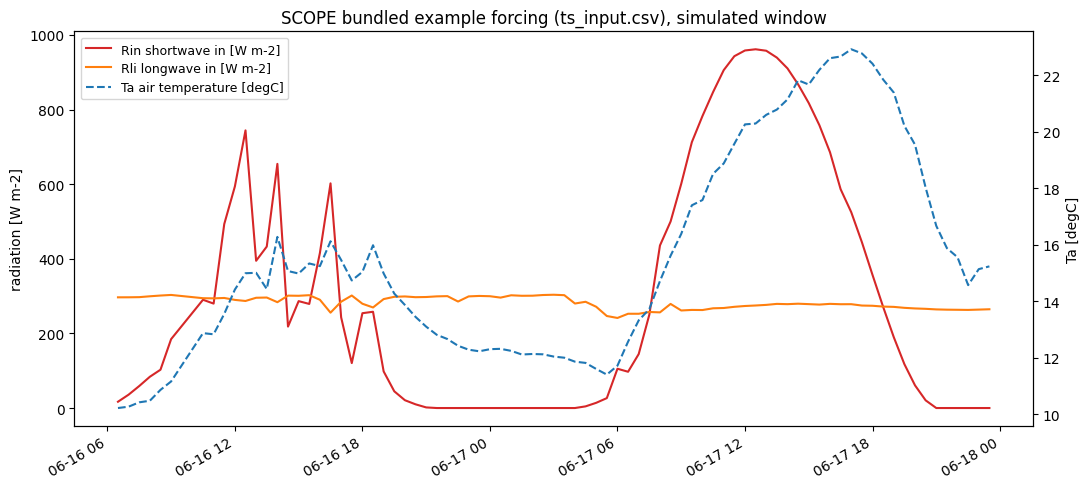

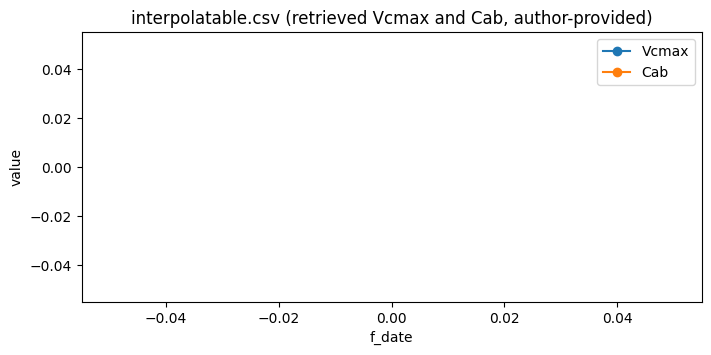

In [ ]:
import matplotlib.pyplot as plt

sel = met[(ts >= start) & (ts < end)].copy()
sel["dt"] = ts[(ts >= start) & (ts < end)]
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(sel.dt, sel.Rin, label="Rin shortwave in [W m-2]", color="tab:red")
ax.plot(sel.dt, sel.Rli, label="Rli longwave in [W m-2]", color="tab:orange")
ax2 = ax.twinx()
ax2.plot(sel.dt, sel.Ta, label="Ta air temperature [degC]", color="tab:blue", ls="--")
ax.set_ylabel("radiation [W m-2]"); ax2.set_ylabel("Ta [degC]")
ax.set_title(f"SCOPE bundled example forcing ({meteo_file}), simulated window")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper left", fontsize=9)
fig.autofmt_xdate(); fig.tight_layout(); plt.show()

if veg_covers:
    sv = veg[(vt >= start - pd.Timedelta(days=1)) & (vt <= end + pd.Timedelta(days=1))]
    ax = sv.plot(x="f_date", y=["Vcmax", "Cab"], style="o-", figsize=(8, 3.5),
                 title="interpolatable.csv (retrieved Vcmax and Cab, author-provided)")
    ax.set_ylabel("value"); plt.show()
else:
    print("interpolatable.csv does not cover the window -> author defaults from input_data_default.csv are used")

### 8. Run SCOPE — scenario (ii): variable ChlF emission efficiency (author default)

Run the **original author entry point** `SCOPE.m` in Octave. In this default mode the photosystem-level
fluorescence efficiency `eta = fs/fo0` (author's `Fluorescencemodel`, `src/fluxes/biochemical.m`) varies
per half hour with the electron-transport rate and non-photochemical quenching — the paper's scenario (ii).
The run processes the half-hourly time series and writes CSV outputs (`fluorescence_scalars.csv`,
`fluorescence.csv`, ...) under `output/`. Expected: a few minutes; the log tail is printed after completion.

**日本語:** 著者のエントリポイント `SCOPE.m` を Octave で実行します。デフォルト（シナリオ ii）では
 光化学電子伝達と NPQ に応じて放射効率 `eta` が半時間ごとに変動します。

In [ ]:
import os, re, subprocess, time

def run_scope(sim_name, eta_mode):
    cfg_path = "/content/SCOPE/input/filenames.csv"
    cfg = open(cfg_path).read()
    cfg = re.sub(r"Simulation_Name,.*", f"Simulation_Name,{sim_name}", cfg)
    open(cfg_path, "w").write(cfg)
    env = dict(os.environ)
    if eta_mode:
        env["SCOPE_ETA_MODE"] = eta_mode
    else:
        env.pop("SCOPE_ETA_MODE", None)  # author default behavior
    log_path = f"/content/log_{sim_name}.txt"
    t0 = time.time()
    with open(log_path, "w") as log:
        proc = subprocess.run(["octave", "--no-gui", "--quiet", "SCOPE.m"],
                              cwd="/content/SCOPE", env=env,
                              stdout=log, stderr=subprocess.STDOUT, timeout=2400)
    dt = time.time() - t0
    tail = "".join(open(log_path).readlines()[-6:])
    print(f"--- {sim_name} (SCOPE_ETA_MODE={eta_mode or 'unset = author default'}) "
          f"exit={proc.returncode} in {dt:.1f}s")
    print(tail)
    if proc.returncode != 0:
        print("".join(open(log_path).readlines()[-40:]))
        raise RuntimeError(f"SCOPE run failed: {sim_name}")
    return proc, dt

proc_var, dt_var = run_scope("mSCOPE_ts_variable", "")

--- mSCOPE_ts_variable (SCOPE_ETA_MODE=unset = author default) exit=0 in 107.9s
time = 17-Jun-2006 21:59:59: 78 / 82
time = 17-Jun-2006 22:30:00: 79 / 82
time = 17-Jun-2006 22:59:59: 80 / 82
time = 17-Jun-2006 23:29:59: 81 / 82
time = 18-Jun-2006: 82 / 82
Elapsed time is 103.996 seconds.



### 8.2 Scenarios (i) constant efficiency and (iii) theoretical maximum

Two additional runs of the *same* pinned code, differing **only** through the documented 4-line hook in
`biochemical.m`: `SCOPE_ETA_MODE=constant` holds `eta ≡ 1` (photosystem-level efficiency constant at its
dark-adapted potential — the paper's scenario (i) operationalization), and `SCOPE_ETA_MODE=max` holds
`eta ≡ (Kf+Kp+Kd)/(Kf+Kd)` — the theoretical maximum for blocked PSII electron transport with minimal
non-photochemical quenching, the paper's scenario (iii). The energy balance and photosynthesis are
unchanged (`eta` does not feed back into them), so this isolates the efficiency effect on F760.

**日本語:** 同一コードで、効率のみを固定したシナリオ (i) と理論最大の (iii) を実行します。
 エネルギー収支・光合成は不変で、効率の影響だけを分離します。

In [ ]:
proc_const, dt_const = run_scope("mSCOPE_ts_constant", "constant")
proc_max, dt_max = run_scope("mSCOPE_ts_max", "max")
print(f"run times: variable {dt_var:.0f}s, constant {dt_const:.0f}s, max {dt_max:.0f}s")

--- mSCOPE_ts_constant (SCOPE_ETA_MODE=constant) exit=0 in 108.1s
time = 17-Jun-2006 21:59:59: 78 / 82
time = 17-Jun-2006 22:30:00: 79 / 82
time = 17-Jun-2006 22:59:59: 80 / 82
time = 17-Jun-2006 23:29:59: 81 / 82
time = 18-Jun-2006: 82 / 82
Elapsed time is 104.209 seconds.



--- mSCOPE_ts_max (SCOPE_ETA_MODE=max) exit=0 in 108.1s
time = 17-Jun-2006 21:59:59: 78 / 82
time = 17-Jun-2006 22:30:00: 79 / 82
time = 17-Jun-2006 22:59:59: 80 / 82
time = 17-Jun-2006 23:29:59: 81 / 82
time = 18-Jun-2006: 82 / 82
Elapsed time is 104.214 seconds.

run times: variable 108s, constant 108s, max 108s


### 9. Parse the SCOPE outputs and compare the scenarios

The author's `bin_to_csv.m` wrote one `fluorescence_scalars.csv` per run; its column `F761`
(`rad.F761 = LoF_(762-640)` in `RTMf.m`) is the simulated canopy fluorescence radiance at ~760 nm in the
observation direction — the paper's F760 [W m-2 um-1 sr-1]. The three scenarios share identical inputs,
so their rows align 1:1 with the simulated window of the input file (verified), and the half-hour axis is
taken from the input time stamps (the author's `bin_to_csv.m` prints the datenum column with an integer
format, which cannot recover the half hour). We quantify how much the constant- and maximum-efficiency
cycles deviate from the variable-efficiency cycle — the paper's central comparison.

**日本語:** 各シナリオの `fluorescence_scalars.csv` から F760（列 F761）の日変化を取り出して比較します。
 時刻軸は入力タイムスタンプから再構築します（著者の CSV 出力は datenum を整数で丸めるため）。
 論文の主張（ unstressed では効率の日変化が小さい）をこの例で定量的に確認します。

In [ ]:
import glob
import numpy as np
import pandas as pd

def load_run(sim_name):
    d = sorted(glob.glob(f"/content/SCOPE/output/{sim_name}_*"))[-1]
    rad = pd.read_csv(f"{d}/radiation.csv", comment="#")
    fs = pd.read_csv(f"{d}/fluorescence_scalars.csv", comment="#")
    assert len(rad) == len(fs), f"row mismatch in {d}"
    out = pd.DataFrame({"Rin": rad.ShortIn, "F760": fs.F761})
    wts = ts[(ts >= start) & (ts <= end)]   # input stamps of the simulated window
    assert len(out) == len(wts), f"output rows {len(out)} != window rows {len(wts)}"
    out["hour"] = wts.dt.hour.values + wts.dt.minute.values / 60
    out["iday"] = wts.dt.dayofyear.values
    out["date"] = wts.dt.normalize().values
    print(d, "| rows:", len(out), "| F760 range [W m-2 um-1 sr-1]:",
          round(float(np.nanmin(out.F760)), 4), "-", round(float(np.nanmax(out.F760)), 4))
    return out, d

ts_v, dir_v = load_run("mSCOPE_ts_variable")
ts_c, dir_c = load_run("mSCOPE_ts_constant")
ts_m, dir_m = load_run("mSCOPE_ts_max")
assert len(ts_v) == len(ts_c) == len(ts_m)

# densest simulated day (the bundled example has a few missing half-hourly slots)
counts = ts_v.groupby("iday").size()
day0_iday = int(counts.idxmax())
day_v = ts_v[ts_v.iday == day0_iday]; day_c = ts_c[ts_c.iday == day0_iday]; day_m = ts_m[ts_m.iday == day0_iday]
day0 = day_v.date.iloc[0]
daylight = day_v.Rin.values > 100
mean_v = np.nanmean(day_v.F760.values[daylight])
rel_const = np.nanmean(np.abs(day_c.F760.values[daylight] - day_v.F760.values[daylight])) / mean_v
rel_max = np.nanmean(np.abs(day_m.F760.values[daylight] - day_v.F760.values[daylight])) / mean_v
print(f"\ncomparison day: {pd.Timestamp(day0).date()} ({len(day_v)} of 48 half-hourly slots present, daytime rows: {daylight.sum()})")
print(f"mean |F760(constant) - F760(variable)| / mean F760(variable) = {rel_const:.1%}")
print(f"mean |F760(max)      - F760(variable)| / mean F760(variable) = {rel_max:.1%}")

/content/SCOPE/output/mSCOPE_ts_variable_2026-10-30-0739 | rows: 82 | F760 range [W m-2 um-1 sr-1]: 0.0 - 2.036
/content/SCOPE/output/mSCOPE_ts_constant_2026-10-30-0741 | rows: 82 | F760 range [W m-2 um-1 sr-1]: 0.0 - 1.566
/content/SCOPE/output/mSCOPE_ts_max_2026-10-30-0743 | rows: 82 | F760 range [W m-2 um-1 sr-1]: 0.0 - 8.3469

comparison day: 2006-06-17 (48 of 48 half-hourly slots present, daytime rows: 27)
mean |F760(constant) - F760(variable)| / mean F760(variable) = 22.6%
mean |F760(max)      - F760(variable)| / mean F760(variable) = 312.4%


### 10. Diurnal F760 cycles and midday fluorescence spectra

Left: the three simulated diurnal cycles of F760 for the densest simulated day, with the shortwave forcing
(`Rin`) on the secondary axis. Right: the simulated fluorescence emission spectrum (640–850 nm) at the
day's brightest half hour for the three scenarios — the characteristic double peak at ~685/~740 nm and the
scenario differences around the O2-A band (~760 nm) that the paper analyses. Both figures are additional
visualizations created for this notebook (not author figures).

**日本語:** 左: 初日の F760 日変化（3 シナリオ）と日射。右: 最も明るい半時間の蛍光スペクトル
（685/740 nm の二峰と 760 nm 付近のシナリオ差）。いずれも本ノートブックで作成した追加可視化です。

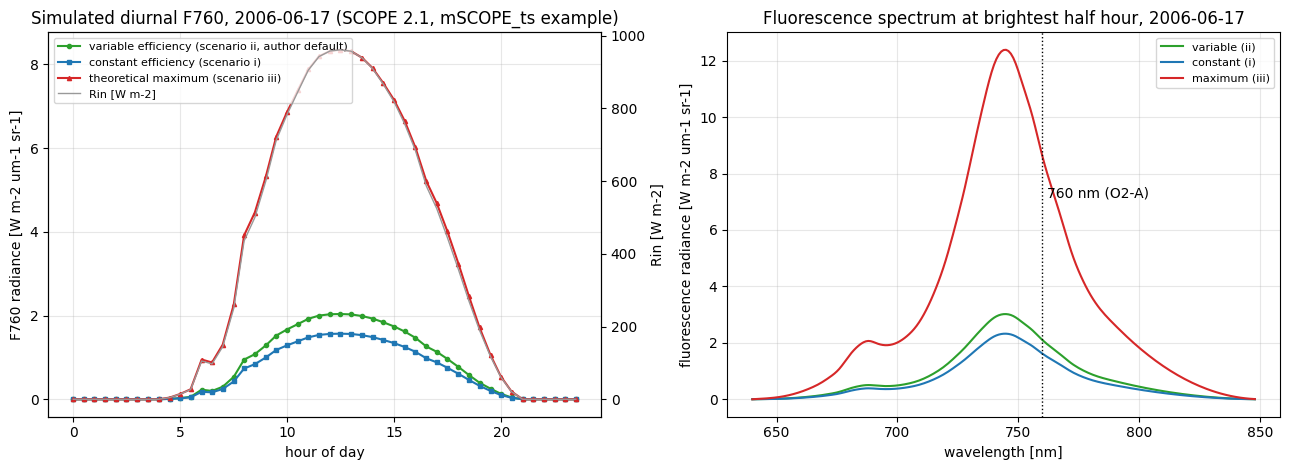

brightest half hour: 12.483333333333333 h | F760 variable/constant/max: 2.03599 1.56604 8.34691


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
ax = axes[0]
ax.plot(day_v.hour, day_v.F760, "-o", ms=3, color="tab:green", label="variable efficiency (scenario ii, author default)")
ax.plot(day_c.hour, day_c.F760, "-s", ms=3, color="tab:blue", label="constant efficiency (scenario i)")
ax.plot(day_m.hour, day_m.F760, "-^", ms=3, color="tab:red", label="theoretical maximum (scenario iii)")
ax2 = ax.twinx()
ax2.plot(day_v.hour, day_v.Rin, color="0.6", lw=1, label="Rin [W m-2]")
ax2.set_ylabel("Rin [W m-2]")
ax.set_xlabel("hour of day"); ax.set_ylabel("F760 radiance [W m-2 um-1 sr-1]")
ax.set_title(f"Simulated diurnal F760, {pd.Timestamp(day0).date()} (SCOPE 2.1, mSCOPE_ts example)")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, fontsize=8, loc="upper left")
ax.grid(alpha=0.3)

ax = axes[1]
wl = np.loadtxt(f"{dir_v}/wlF.txt")
i_mid = int(np.nanargmax(np.where(daylight, day_v.Rin.values, -1)))
for out, d, c, lab in [(day_v, dir_v, "tab:green", "variable (ii)"),
                       (day_c, dir_c, "tab:blue", "constant (i)"),
                       (day_m, dir_m, "tab:red", "maximum (iii)")]:
    spec = pd.read_csv(f"{d}/fluorescence.csv", comment="#")
    row = spec.iloc[int(day_v.index[i_mid])]
    ax.plot(wl, row.values[:len(wl)], color=c, label=lab)
ax.axvline(760, color="k", ls=":", lw=1)
ax.text(762, ax.get_ylim()[1] * 0.55, "760 nm (O2-A)")
ax.set_xlabel("wavelength [nm]"); ax.set_ylabel("fluorescence radiance [W m-2 um-1 sr-1]")
ax.set_title(f"Fluorescence spectrum at brightest half hour, {pd.Timestamp(day0).date()}")
ax.legend(fontsize=8); ax.grid(alpha=0.3)
fig.tight_layout(); plt.show()
print("brightest half hour:", float(day_v.hour.iloc[i_mid]), "h | F760 variable/constant/max:",
      float(day_v.F760.iloc[i_mid]), float(day_c.F760.iloc[i_mid]), float(day_m.F760.iloc[i_mid]))

### 11. Results table and CSV export

Small quantitative summary of the comparison, exported as CSV inside the Colab VM
(`/content/f760_scenario_comparison.csv`). Units as in SCOPE's output files.

**日本語:** シナリオ比較の要約表（CSV エクスポート付き）。

In [ ]:
summary = pd.DataFrame({
    "scenario": ["variable (ii)", "constant (i)", "maximum (iii)"],
    "F760 daytime mean [W m-2 um-1 sr-1]": [
        float(np.nanmean(day_v.F760.values[daylight])),
        float(np.nanmean(day_c.F760.values[daylight])),
        float(np.nanmean(day_m.F760.values[daylight]))],
    "F760 daytime max [W m-2 um-1 sr-1]": [
        float(np.nanmax(day_v.F760.values[daylight])),
        float(np.nanmax(day_c.F760.values[daylight])),
        float(np.nanmax(day_m.F760.values[daylight]))],
})
summary["mean |diff vs variable| [%]"] = [0.0, 100 * rel_const, 100 * rel_max]
summary.style if False else None
print(summary.to_string(index=False))
summary.to_csv("/content/f760_scenario_comparison.csv", index=False)
print("\nsaved /content/f760_scenario_comparison.csv")

     scenario  F760 daytime mean [W m-2 um-1 sr-1]  F760 daytime max [W m-2 um-1 sr-1]  mean |diff vs variable| [%]
variable (ii)                             1.307591                             2.03599                     0.000000
 constant (i)                             1.012084                             1.56604                    22.599297
maximum (iii)                             5.392321                             8.34691                   312.385971

saved /content/f760_scenario_comparison.csv


## Interpretation, limitations, validation record

**What this demonstrates.** With the authors' own model and bundled example inputs, the F760 diurnal cycle
responds to the ChlF emission-efficiency treatment as the paper argues: the variable-efficiency cycle (ii)
stays within the printed relative deviation of the constant-efficiency cycle (i) for this *unstressed*
example, while the theoretical maximum (iii) — blocked PSII electron transport, minimal NPQ — raises F760
several-fold above both. This is the model-based counterpart of the paper's conclusion that diurnal
variations of the photosystem-level efficiency are modest in unstressed crops, and that a chemically
blocked system corresponds to a much higher emission efficiency. In the model the relative efficiency
`eta = fs/fo0` is 1 when photochemistry runs at its dark-adapted capacity and grows towards ~5.3 as PSII
saturates, so the constant run (eta ≡ 1) is the lower envelope and the measured deviation above quantifies
how much the efficiency actually moves during this day.

**Limitations / differences from the paper.**
- The paper's field measurements (rice, alfalfa, treated grass) are **not public**; no measurement
  comparison is reproduced. This notebook is a *simulation-only partial demonstration*.
- The paper's exact 2016 SCOPE version is untagged; tag 2.1 — the earliest tag bundling the required
  time-series example inputs — is used. Equations were revised between versions (Yang et al. 2021), so
  absolute values are tag-2.1 values.
- The constant for scenario (i) is an AI-defined operationalization (`eta ≡ 1`, the dark-adapted
  potential with fully functional photochemistry): the paper's full text could not be retrieved through
  any attempted route
  (ScienceDirect HTTP 400; Twente and Milano-Bicocca repositories 403; OpenAlex has no copy), so the
  paper's exact constant could not be verified. The *variable* scenario (ii) is the authors' own default.
- The layered leaf-trait anchors and the simulation window are set to the actual bundled example period;
  layer values are the author's own defaults. Input I/O patches change no scientific operation; `eta`
  does not feed back into the energy balance, so the scenario hook isolates the efficiency effect.
- A single short example is not verification of the paper's dataset-level results.

**Provenance.** Code: `Christiaanvandertol/SCOPE` tag 2.1, commit `2c2b89b5884dd99a872c3e1430cf59761c8541cb`
(GPL v3). Inputs: `input/dataset mSCOPE_ts` from the same commit. The PhenoPaper investigation
`p-c6122665cc225259f0e4d37e864ce925-20261030T052550Z-2367211` was used as prior research guidance.

**日本語:** 圃場データが公開されていないため、再現はシミュレーション部分に限定されます。使用したのは著者タグ 2.1
（論文時点のバージョンは未タグ）。シナリオ (i) の「一定値」は論文本文が入手できないため AI が定義した運用化
（暗順応のポテンシャル値）であり、シナリオ (ii) は著者コードのデフォルトそのものです。単一の短い例は
論文のデータセット全体の結果の検証ではありません。

## References
1. van der Tol, C., et al. (2016), RSE 186:663–677, DOI 10.1016/j.rse.2016.09.021
2. Yang, P., Prikaziuk, E., Verhoef, W., van der Tol, C. (2021), *SCOPE 2.0*, Geosci. Model Dev. 14:4643–4672
3. van der Tol, C., et al. (2009), *An integrated model...*, Biogeosciences 6:3109–3129
4. SCOPE repository: https://github.com/Christiaanvandertol/SCOPE (tag 2.1, GPL v3)

### 12.2 Environment record

Print the actual software versions used by this validated run.

**日本語:** 検証に使用したソフトウェアのバージョンを記録します。

In [ ]:
import subprocess, sys
import matplotlib
print("Octave:", subprocess.run(["octave", "--version"], capture_output=True, text=True).stdout.splitlines()[0])
print("Python:", sys.version.split()[0], "| pandas:", pd.__version__, "| numpy:", np.__version__,
      "| matplotlib:", matplotlib.__version__)
print("Pinned SCOPE commit: 2c2b89b5884dd99a872c3e1430cf59761c8541cb (tag 2.1)")
print("Scenario run wall times (s): variable %.0f, constant %.0f, max %.0f" % (dt_var, dt_const, dt_max))

Octave: GNU Octave, version 8.4.0
Python: 3.13.18 | pandas: 2.2.3 | numpy: 2.1.3 | matplotlib: 3.10.0
Pinned SCOPE commit: 2c2b89b5884dd99a872c3e1430cf59761c8541cb (tag 2.1)
Scenario run wall times (s): variable 108, constant 108, max 108
